# Imports

In [1]:
from pesummary.io import read;

from pycbc.inference.io import loadfile;
from pycbc import conversions as cvs;
from pycbc import cosmology as cos;

import numpy as np
import matplotlib.pyplot as pp
import seaborn as sns

import pandas as pd

pp.rcParams.update({
    "text.usetex": False,  # 启用 LaTeX 渲染
    # "font.family": "serif",  # 可选：设置字体为衬线字体（与 LaTeX 风格一致）
    # "font.serif": ["Times New Roman", "Computer Modern Roman"],  # 可选：指定字体
});
pp.rcParams.update(pp.rcParamsDefault);

/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


$N = - \frac{3}{128}\frac{1}{\eta}\pi^{-5/3}\\
$
\begin{aligned}
-\phi = Nf^{5/3}(\cdots + \phi_j f^{j/3} + \phi_{jl} f^{j/3}\log{f})
    = -f^{5/3}(\cdots + \psi_j f^{j/3} + \psi_{jl} f^{j/3}\log{f})\\
\end{aligned}

\begin{aligned}
-\phi^\prime = N((\cdots)^\prime + \left(\frac{j-8}{3}\phi_j + \phi_{jl}\right) f^{(j-8)/3} + \frac{j-8}{3}\phi_{jl} f^{(j-8)/3}\log{f})\\
    = (M)^{-8/3} \frac{5}{128 \pi^{5/3}}((\cdots)^\prime + \left(\frac{8-j}{5}\phi_j - \frac{3}{5}\phi_{jl}\right) f^{(j-8)/5} + \frac{8-j}{3}\phi_{jl} f^{(j-8)/3}\log{f})
    = \\
\end{aligned}

# Util Function

In [2]:
def augment_OGC_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    temp = {}
    temp['spin1x'], temp['spin1y'], temp['spin1z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    temp['spin2x'], temp['spin2y'], temp['spin2z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    samples = samples.add_fields(temp['spin1x'], 'spin1x')
    samples = samples.add_fields(temp['spin1y'], 'spin1y')
    samples = samples.add_fields(temp['spin1z'], 'spin1z')
    samples = samples.add_fields(temp['spin2x'], 'spin2x')
    samples = samples.add_fields(temp['spin2y'], 'spin2y')
    samples = samples.add_fields(temp['spin2z'], 'spin2z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

def augment_OGC_XAS_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    # samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    # samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    def chi_hat_PN(m1,m2,chi1,chi2) :
        eta = cvs.eta_from_mass1_mass2(m1,m2)
        N = 1 - 76/133*eta
        chi_eff = cvs.chi_eff(m1,m2,chi1,chi2)
        term = -38/113*eta*(chi1+chi2)
        chi_PN = chi_eff + term
        return chi_PN / N
        # cvs.chi_eff(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z'])
    samples = samples.add_fields(chi_hat_PN(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z']), 'chi_hat_PN')
    
    temp = {}
    # temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    # temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    # samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    # samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    # samples = samples.add_fields(samples['spin1z'], 'spin1z')
    # samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    # samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    # samples = samples.add_fields(samples['spin2z'], 'spin2z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

# Data Reading and Pre-processing

## OGC Posteriors

In [3]:
posteriors_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GW250114"

samples = {}
samples['GW150914'] = {}
samples['GW150914_095045'] = {}
samples['GW151012'] = {}
samples['GW151226'] = {}
samples['GW170104'] = {}
samples['GW170608'] = {}
samples['GW170729'] = {}
samples['GW170809'] = {}
samples['GW170818'] = {}
samples['GW170823'] = {}
samples['GW170814'] = {}
samples['GW200129_065458'] = {}
samples['GW250114'] = {}

event_id = "GW250114"


In [4]:
csv_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv"

cpsijs = ['cpsi2', 'cpsi3', 'cpsi4', 'cpsi5l', 'cpsi6', 'cpsi7']
dchijs = ['dchi2', 'dchi3', 'dchi4', 'dchi5l', 'dchi6', 'dchi7']
orders = ['2', '3', '4', '5l', '6', '7']

results = []

for dchij in dchijs :
    results.append(dict(
    event_name=event_id,
    deviation_name=dchij,
    result_posterior_path='',
    posterior_file_name='' + event_id + f'_{dchij}.hdf',
    label="" + event_id + f", {dchij}"
))

In [5]:
# for result in results:
#     fp = loadfile(posteriors_path + '/' + result['result_posterior_path'] + '/' + result['posterior_file_name'], 'r')
#     samples[result['event_name']][result['deviation_name']] = fp.read_samples(fp['samples'].keys())
#     samples[result['event_name']][result['deviation_name']] = augment_OGC_result(samples[result['event_name']][result['deviation_name']])
#     samples[result['event_name']][result['deviation_name']] = pd.DataFrame(samples[result['event_name']][result['deviation_name']])
#     samples[result['event_name']][result['deviation_name']].attrs['label'] = result['label']

In [6]:
for result in results:
    print(posteriors_path + '/' + result['result_posterior_path'] + '/' + result['posterior_file_name'])
    fp = loadfile(posteriors_path + '/' + result['result_posterior_path'] + '/' + result['posterior_file_name'], 'r')
    samples[result['event_name']][result['deviation_name']] = fp.read_samples(fp['samples'].keys())
    samples[result['event_name']][result['deviation_name']] = augment_OGC_result(samples[result['event_name']][result['deviation_name']])
    samples[result['event_name']][result['deviation_name']] = pd.DataFrame(samples[result['event_name']][result['deviation_name']])
    samples[result['event_name']][result['deviation_name']].attrs['label'] = result['label']

/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GW250114//GW250114_dchi2.hdf


/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GW250114//GW250114_dchi3.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GW250114//GW250114_dchi4.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GW250114//GW250114_dchi5l.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GW250114//GW250114_dchi6.hdf
/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GW250114//GW250114_dchi7.hdf


In [7]:
for j, dchij in enumerate(dchijs[:]) :
    samples[event_id][dchij][["mass1","mass2","spin1z","spin2z",dchij]].to_csv(csv_path+'/' + event_id + '/' + f'dphi_{orders[j]}' + '_IMRP_posterior.csv', index=False)

# Visualisation

In [8]:
import corner

quantiles = [0.05, 0.50, 0.95]

def plot_parameter(samples: pd.DataFrame, parameter_name, label, type='plot', bins=100, boundary_color='black', quantiles=[0.10, 0.50, 0.90], vlines_colors='blue', if_plot_vlines=False) :
    p = pd.cut(samples[parameter_name], bins=bins).value_counts(sort=False) / len(samples[parameter_name])
    x = pd.cut(samples[parameter_name], bins=bins).cat.categories.left.tolist()
    if type=='plot' :
        pp.plot(x, p, color=boundary_color, label=label)
    if type=='step' :
        pp.step(x, p, color=boundary_color, label=label)
    if type=='violin' :
        sns.violinplot(x=x, y=p)
    if if_plot_vlines:
        pp.vlines(samples[parameter_name].quantile(quantiles).values,
            ymin=0.0, ymax=max(p),
            linestyles = "dashed",
            colors=vlines_colors)
        
def get_label_str(samples, parameter_name, parameter_latex, quantiles=[0.10, 0.50, 0.90]) :
    label = samples.attrs['label']
    BCI = samples[parameter_name].quantile(quantiles).values
    left = np.round(BCI[1] - BCI[0], 3)
    median = np.round(BCI[1], 3)
    right= np.round(BCI[2] - BCI[1], 3)

    label += '; '
    label += parameter_latex
    label += ' = '
    label += f'${median}_{{-{left} }}^{{+{right} }}$'
    return label

/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


<>:30: SyntaxWarning: invalid escape sequence '\c'
<>:30: SyntaxWarning: invalid escape sequence '\c'
<>:30: SyntaxWarning: invalid escape sequence '\c'
<>:30: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_3913/1975425041.py:30: SyntaxWarning: invalid escape sequence '\c'
  labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",f"$\\psi_{{{orders[j]}}}$"])
/tmp/ipykernel_3913/1975425041.py:30: SyntaxWarning: invalid escape sequence '\c'
  labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",f"$\\psi_{{{orders[j]}}}$"])


文件夹已准备就绪：/mnt/d/Documents/workspace/课题/论文/figs/GW250114/posteriors


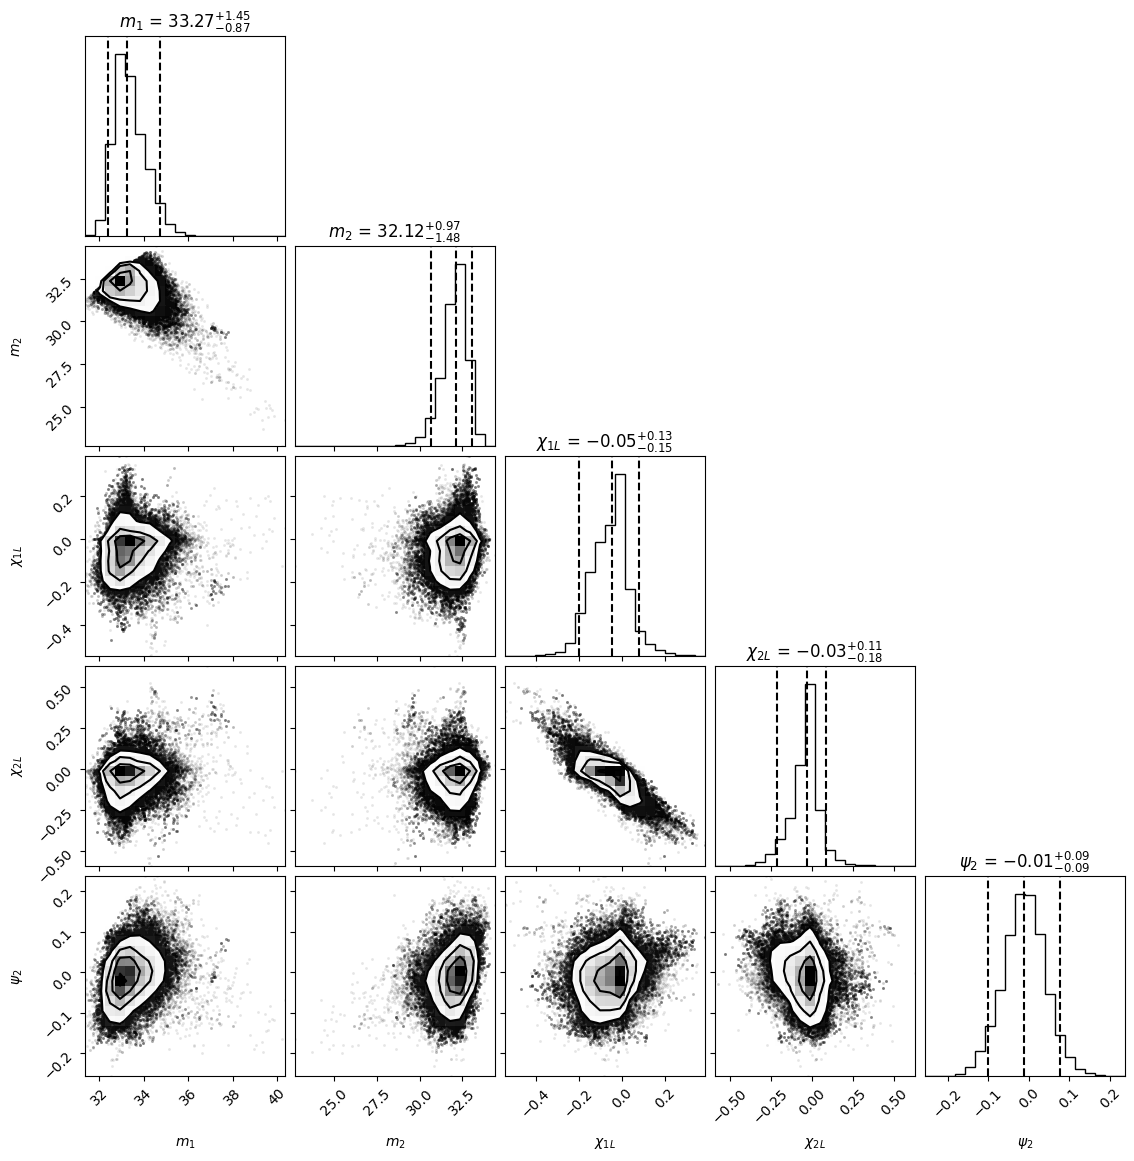

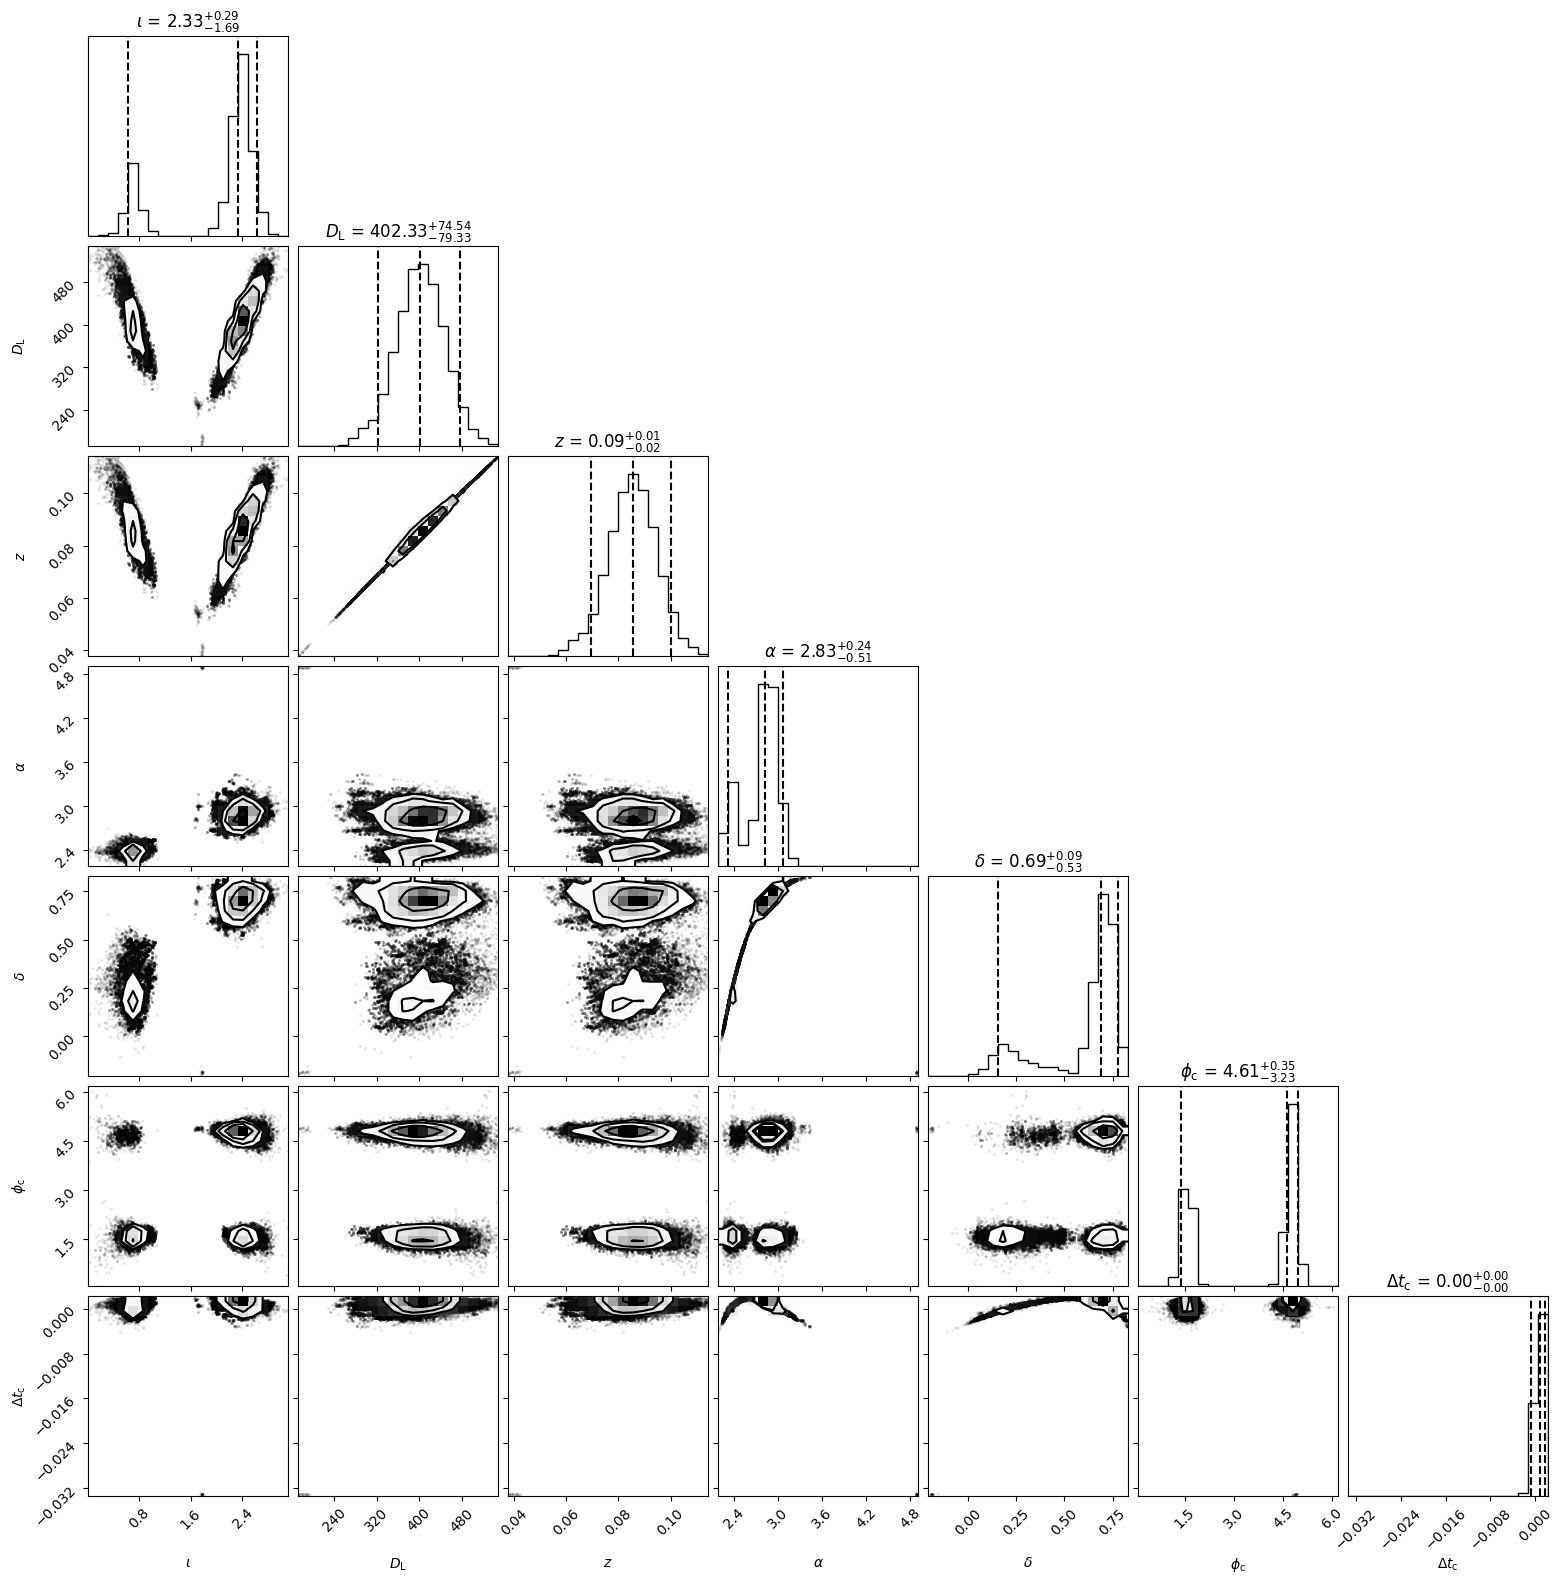

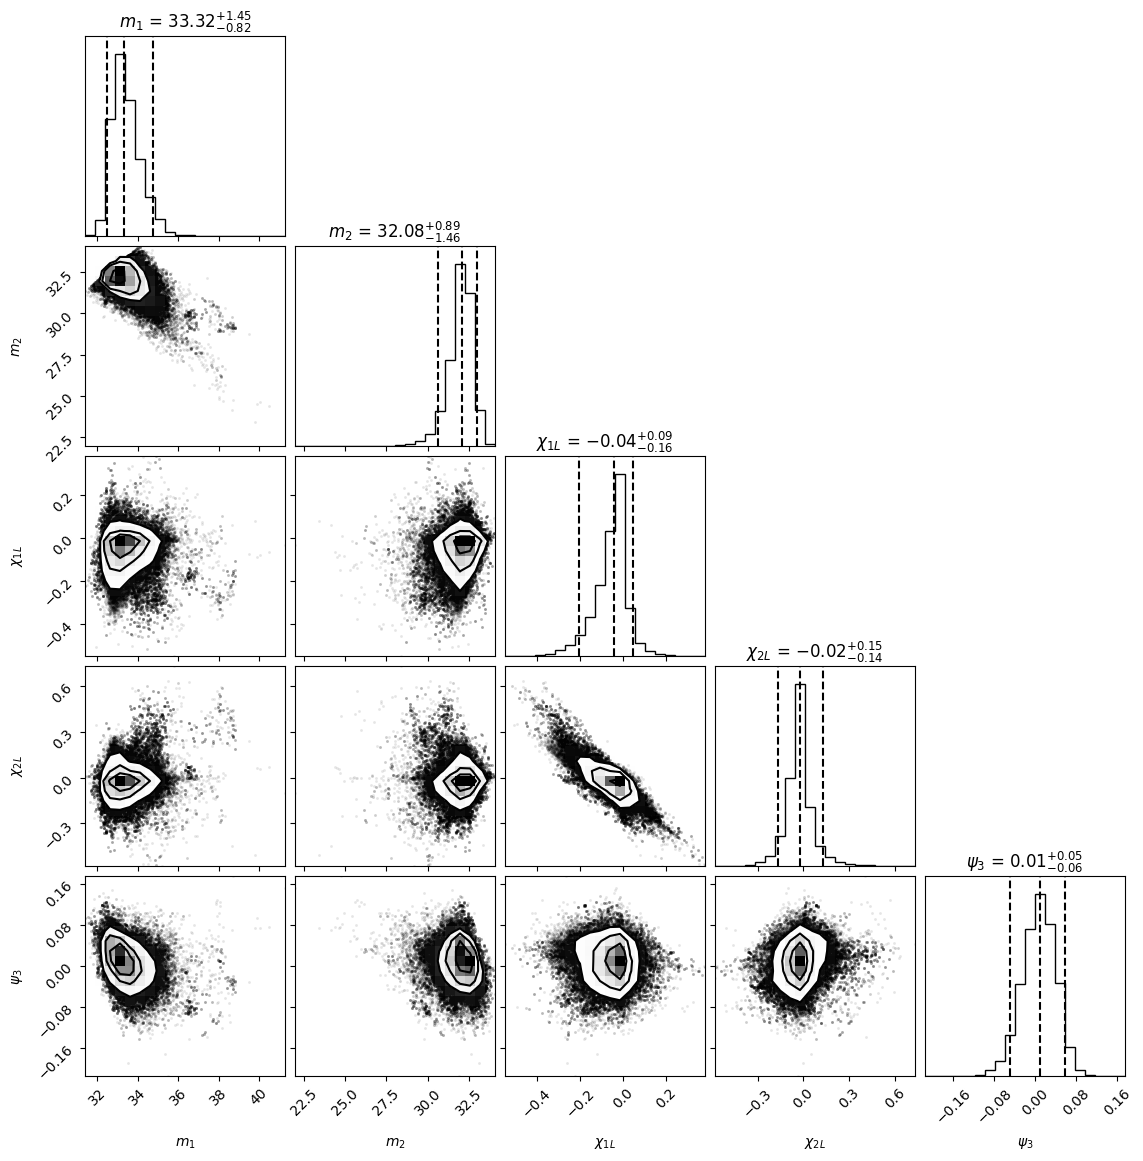

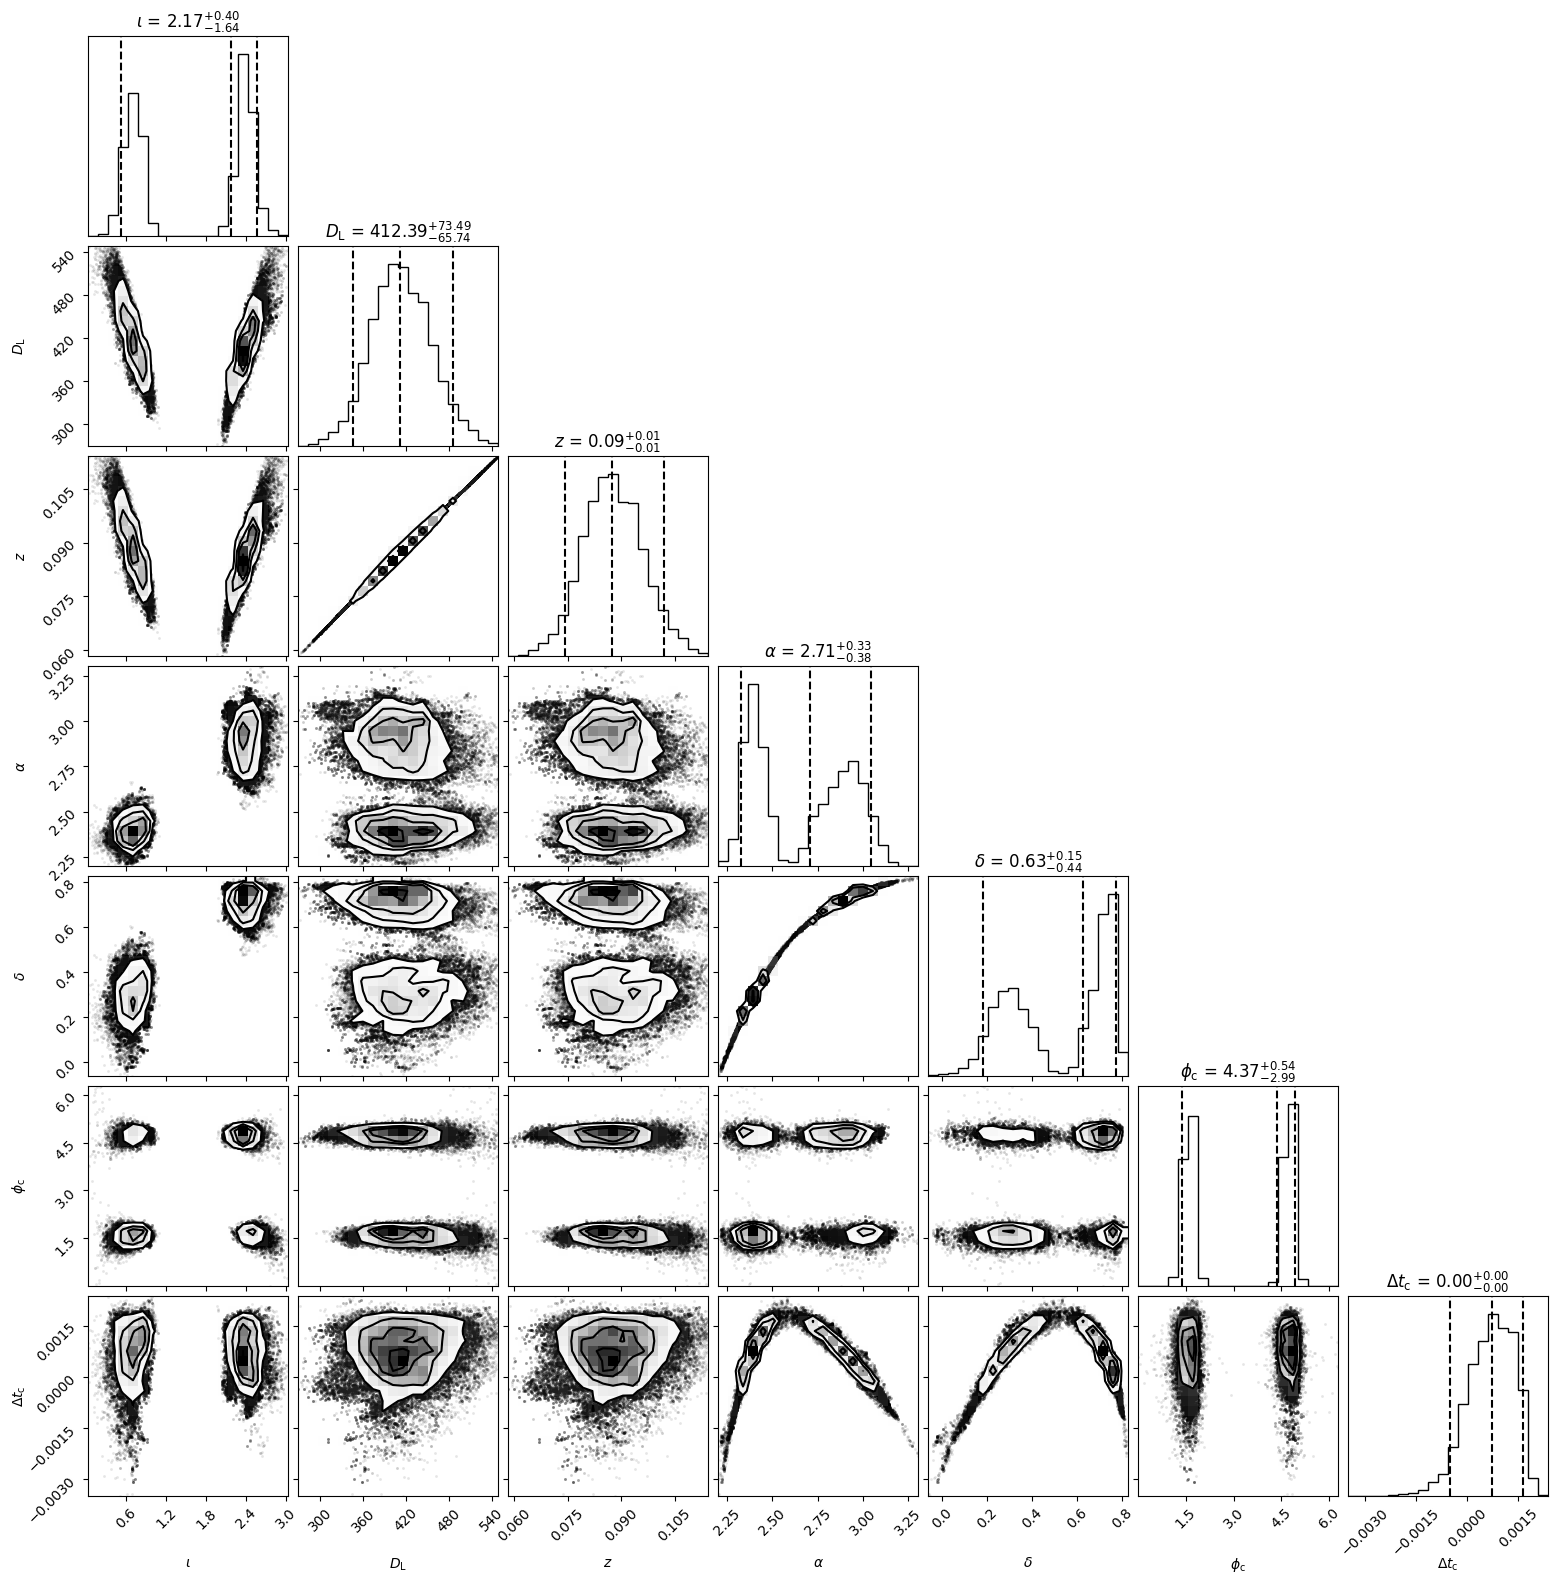

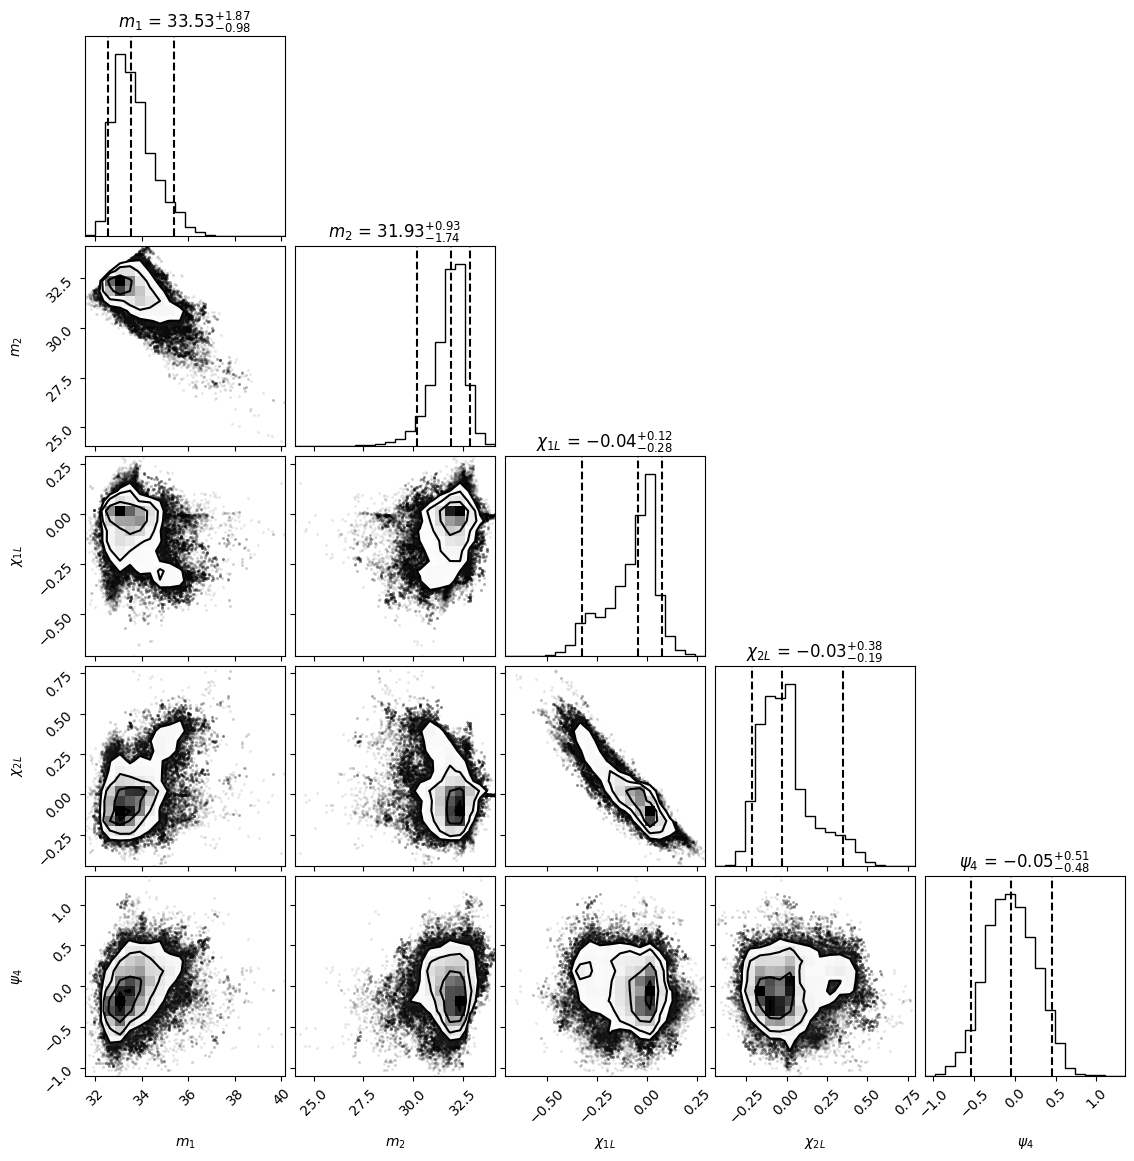

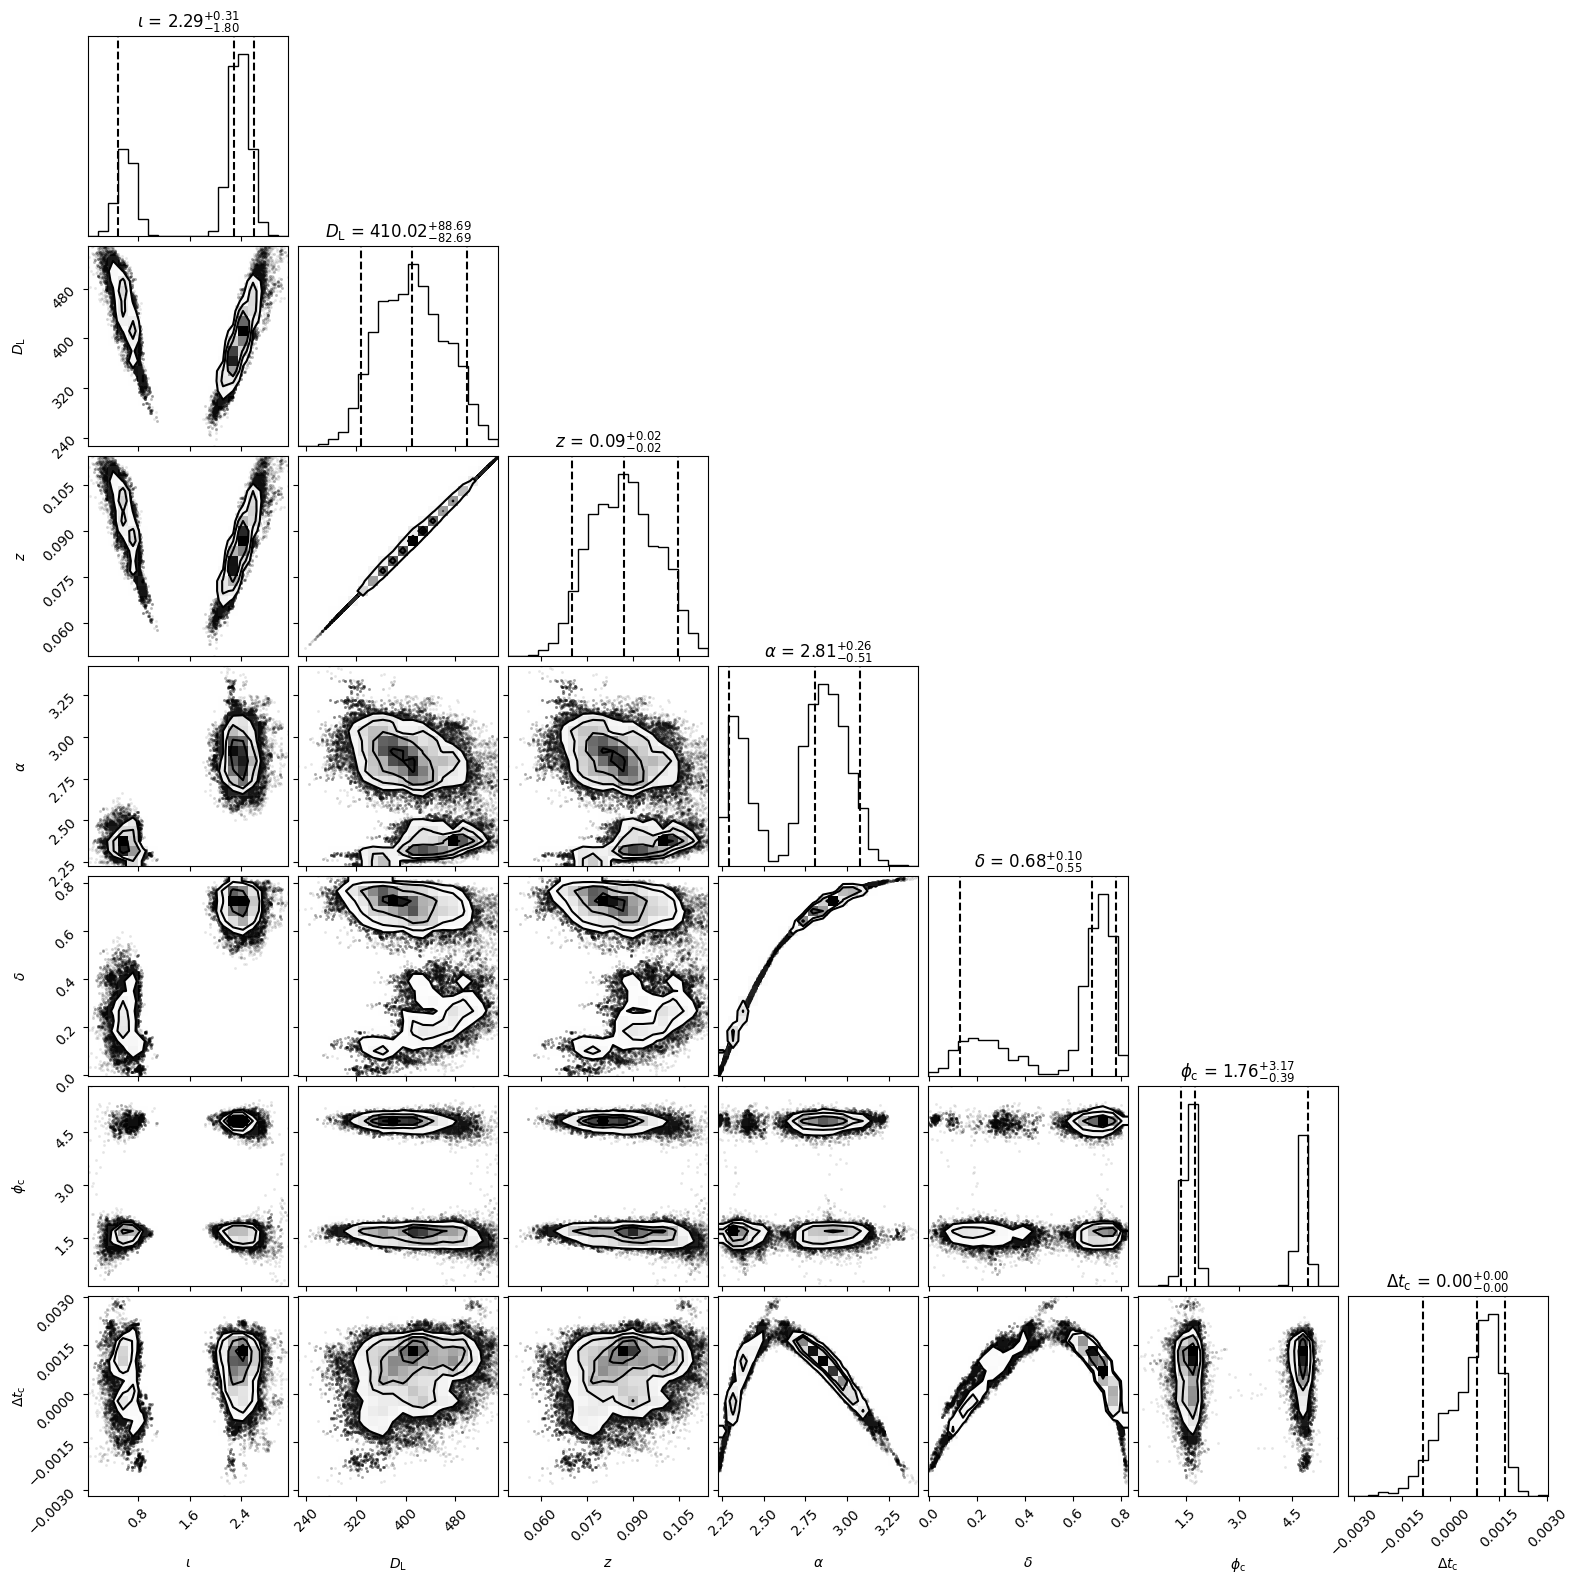

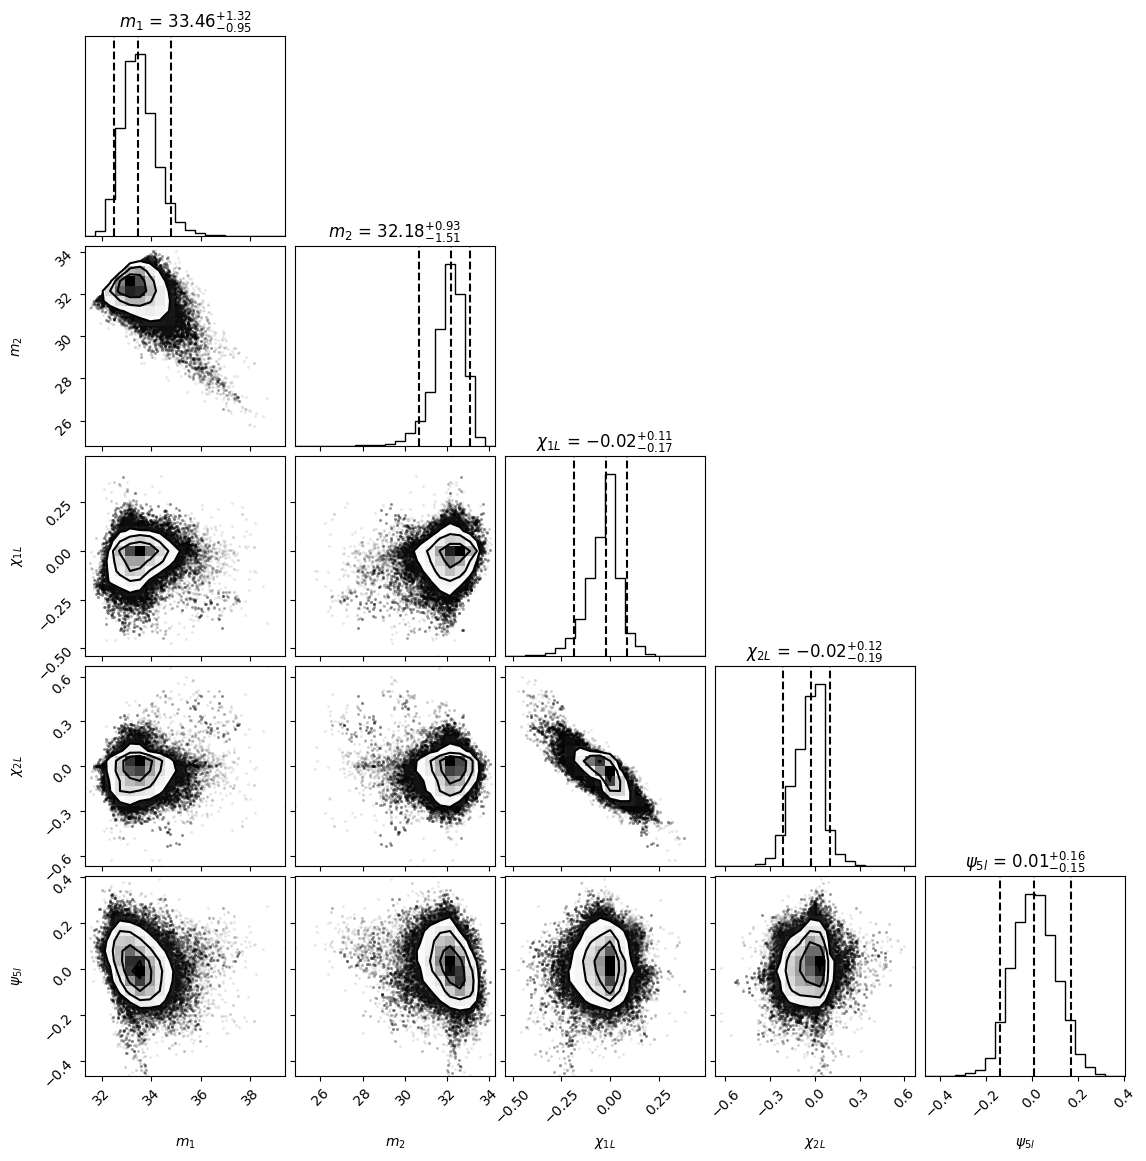

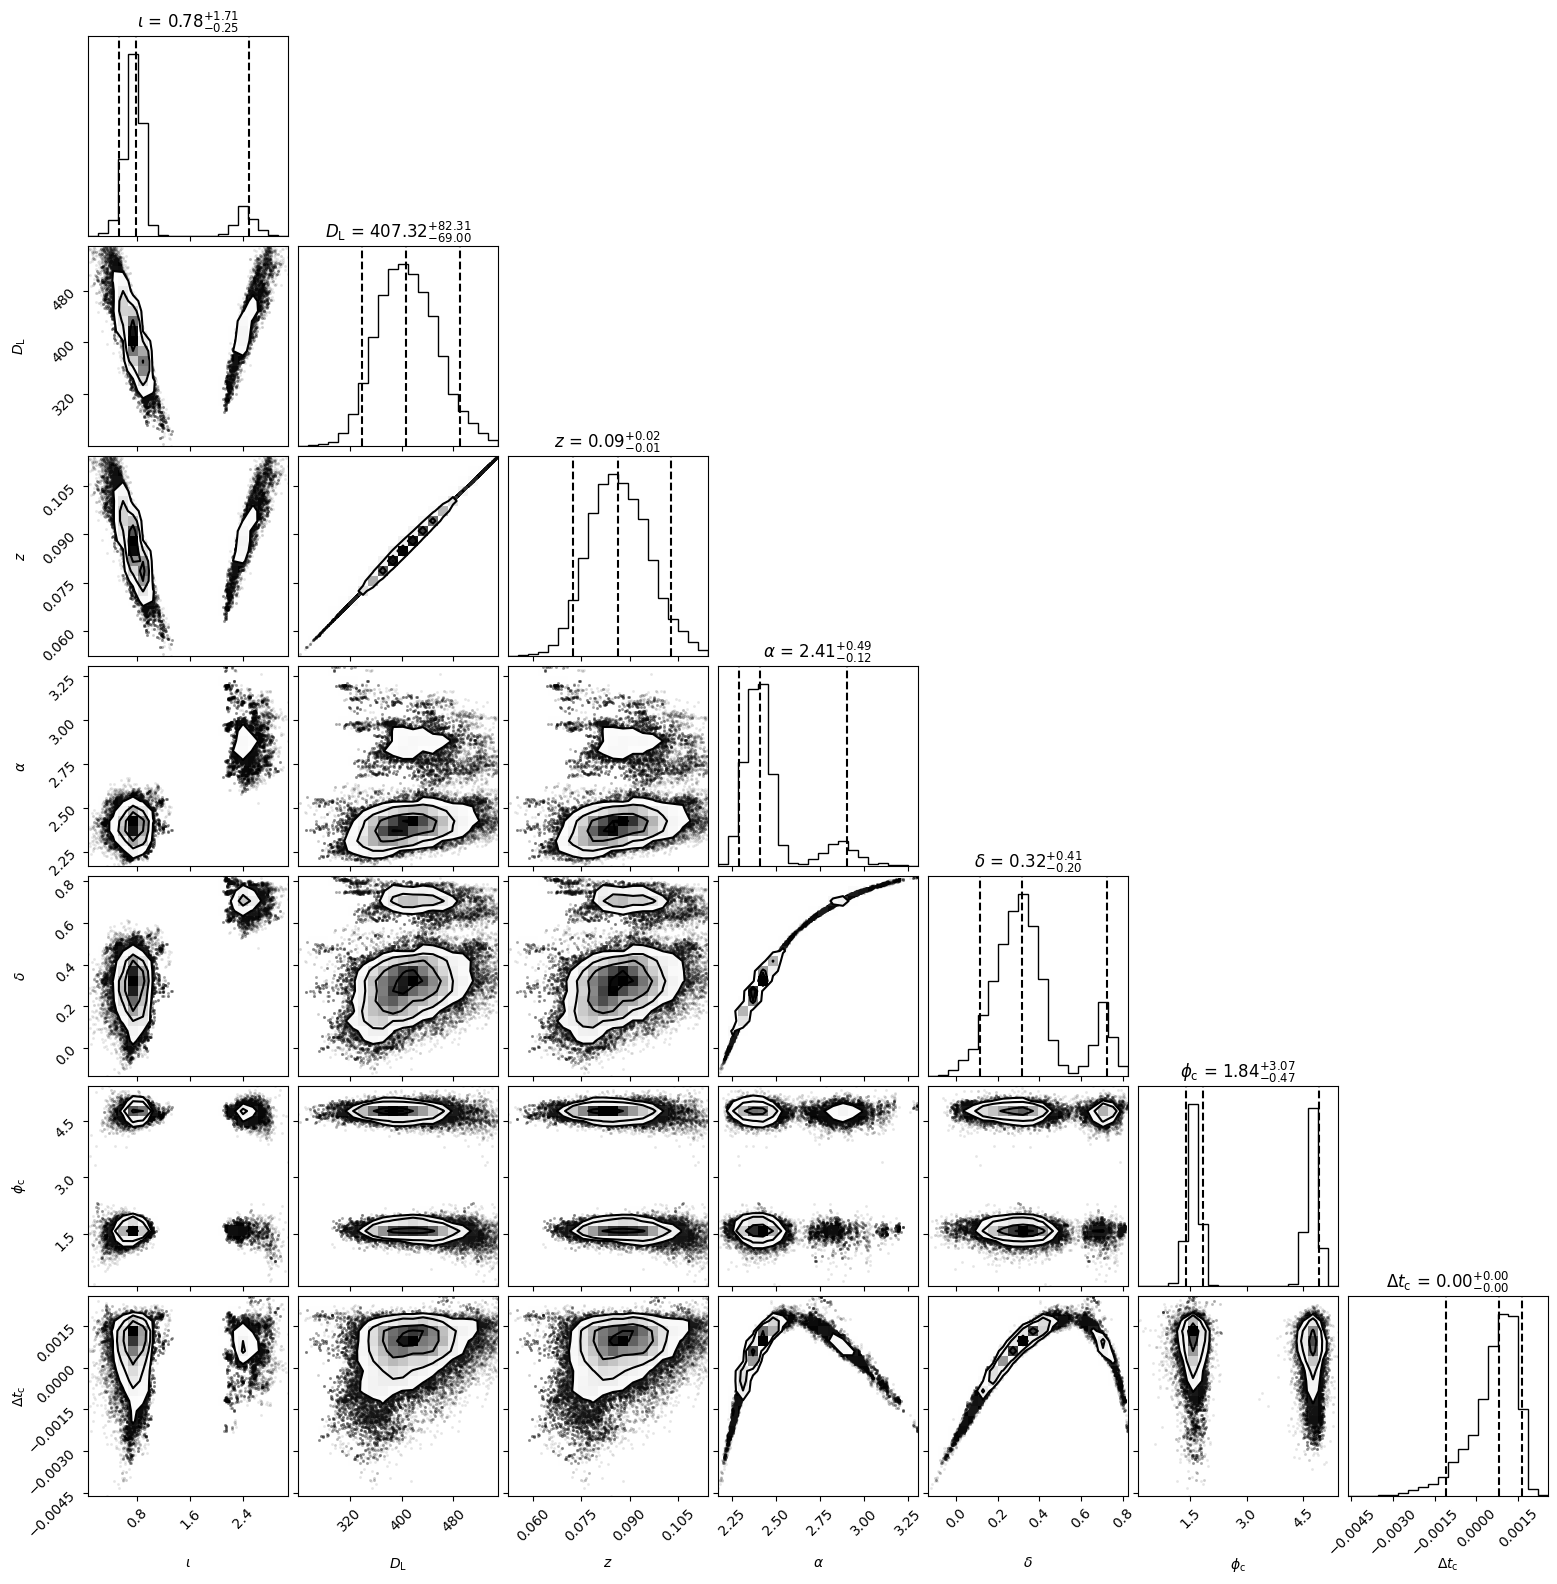

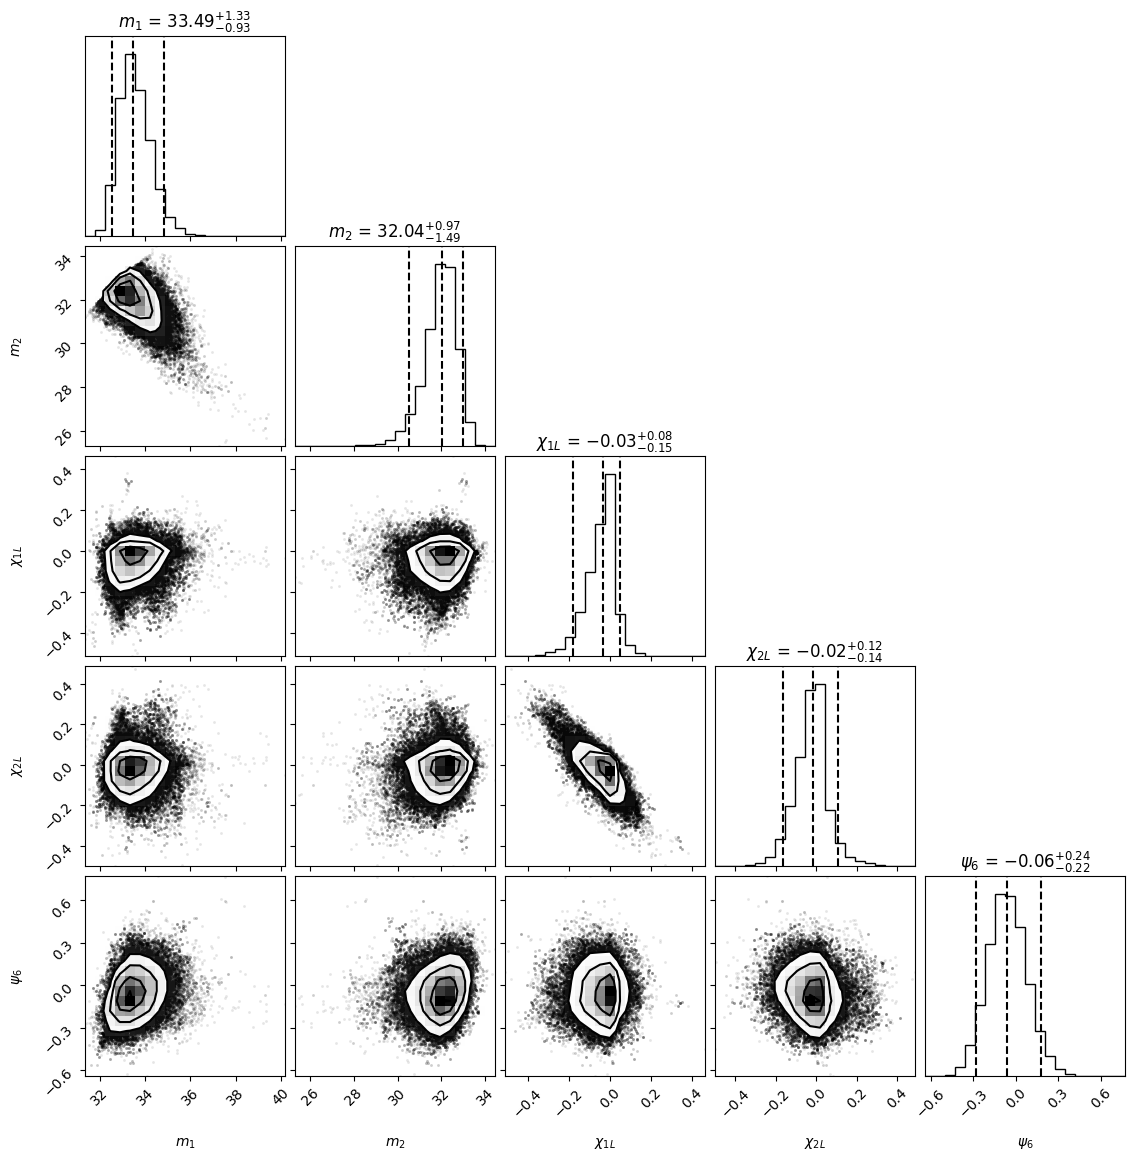

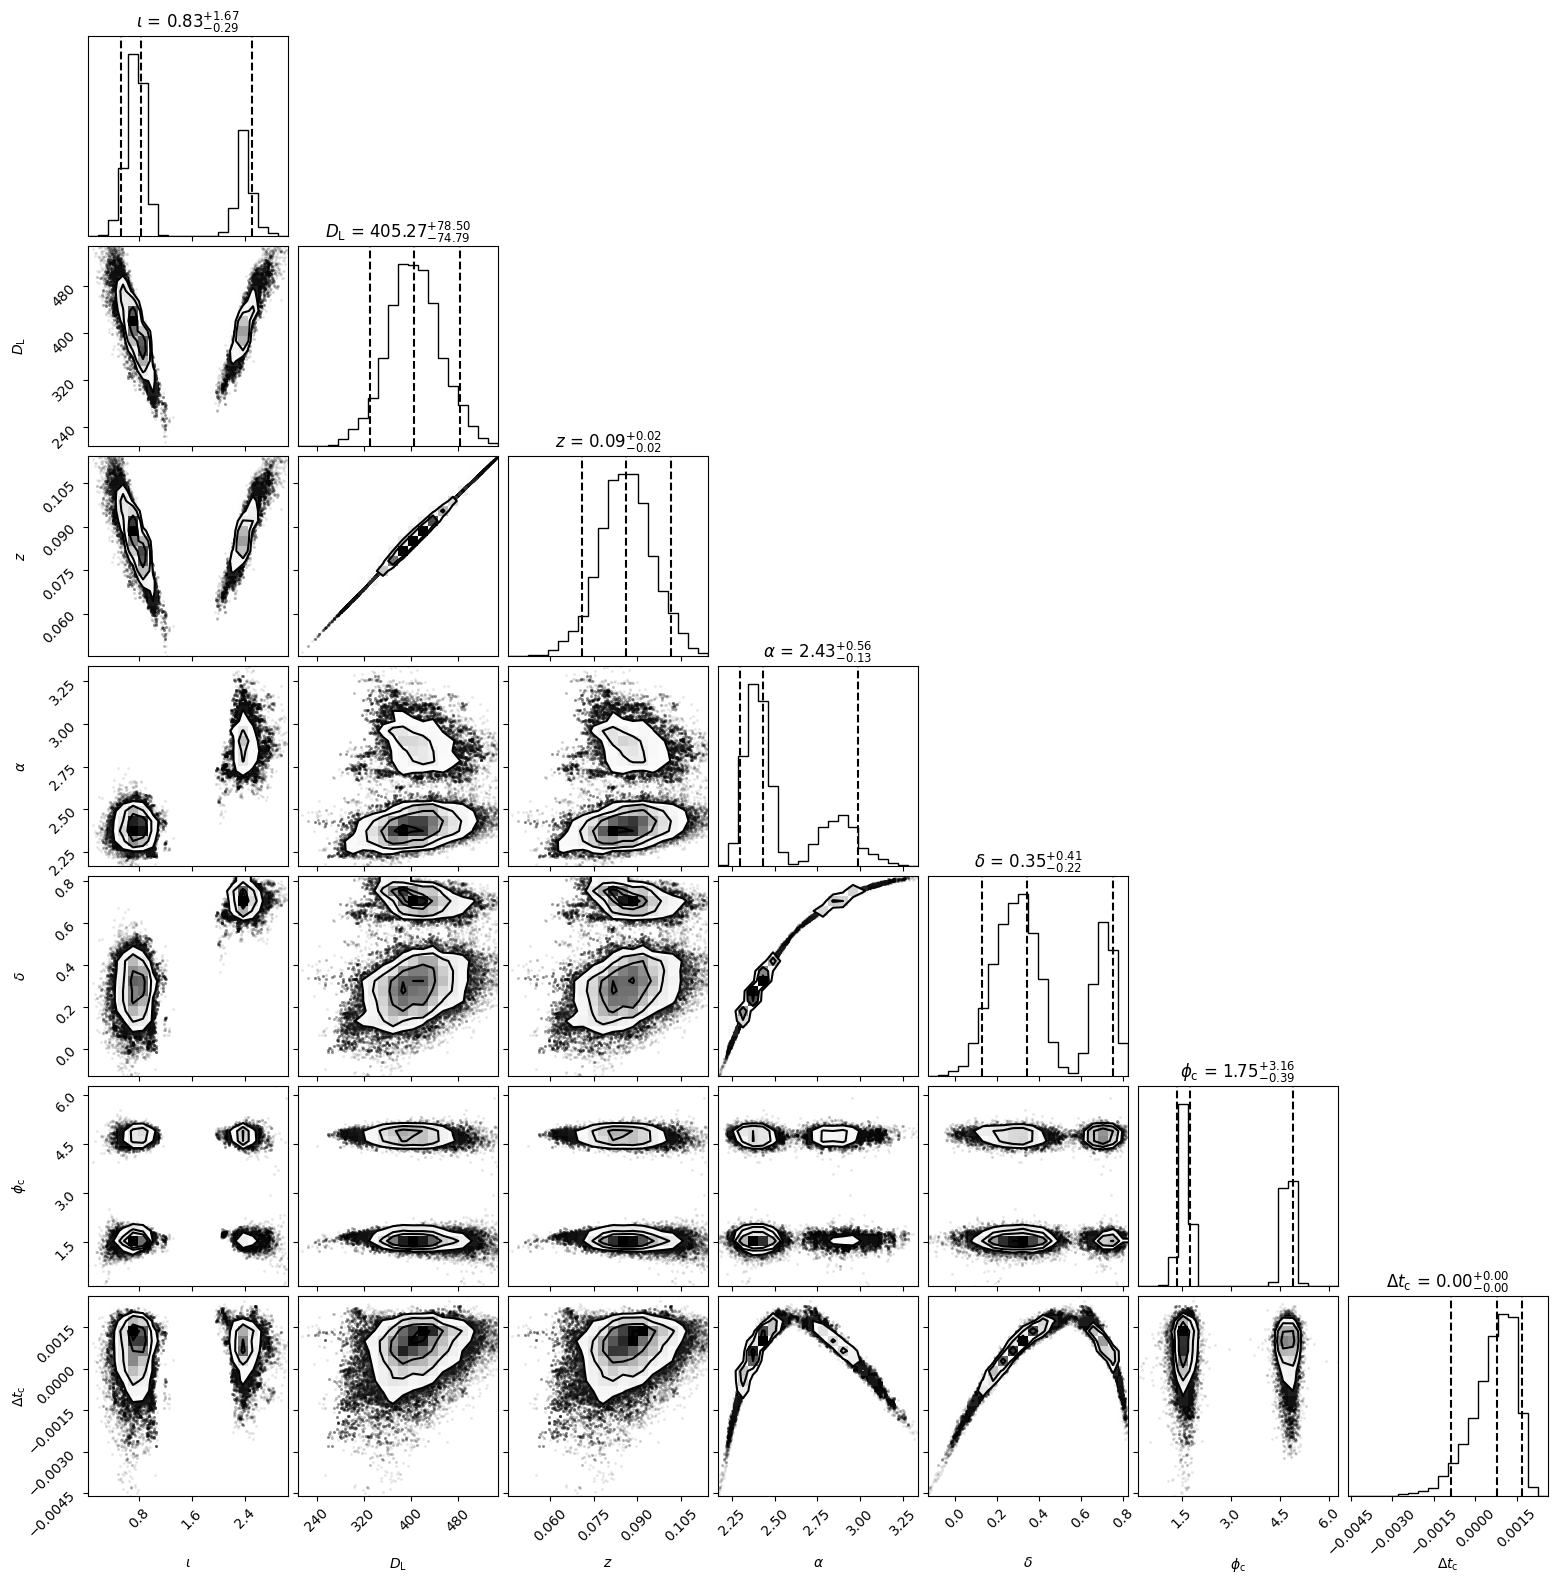

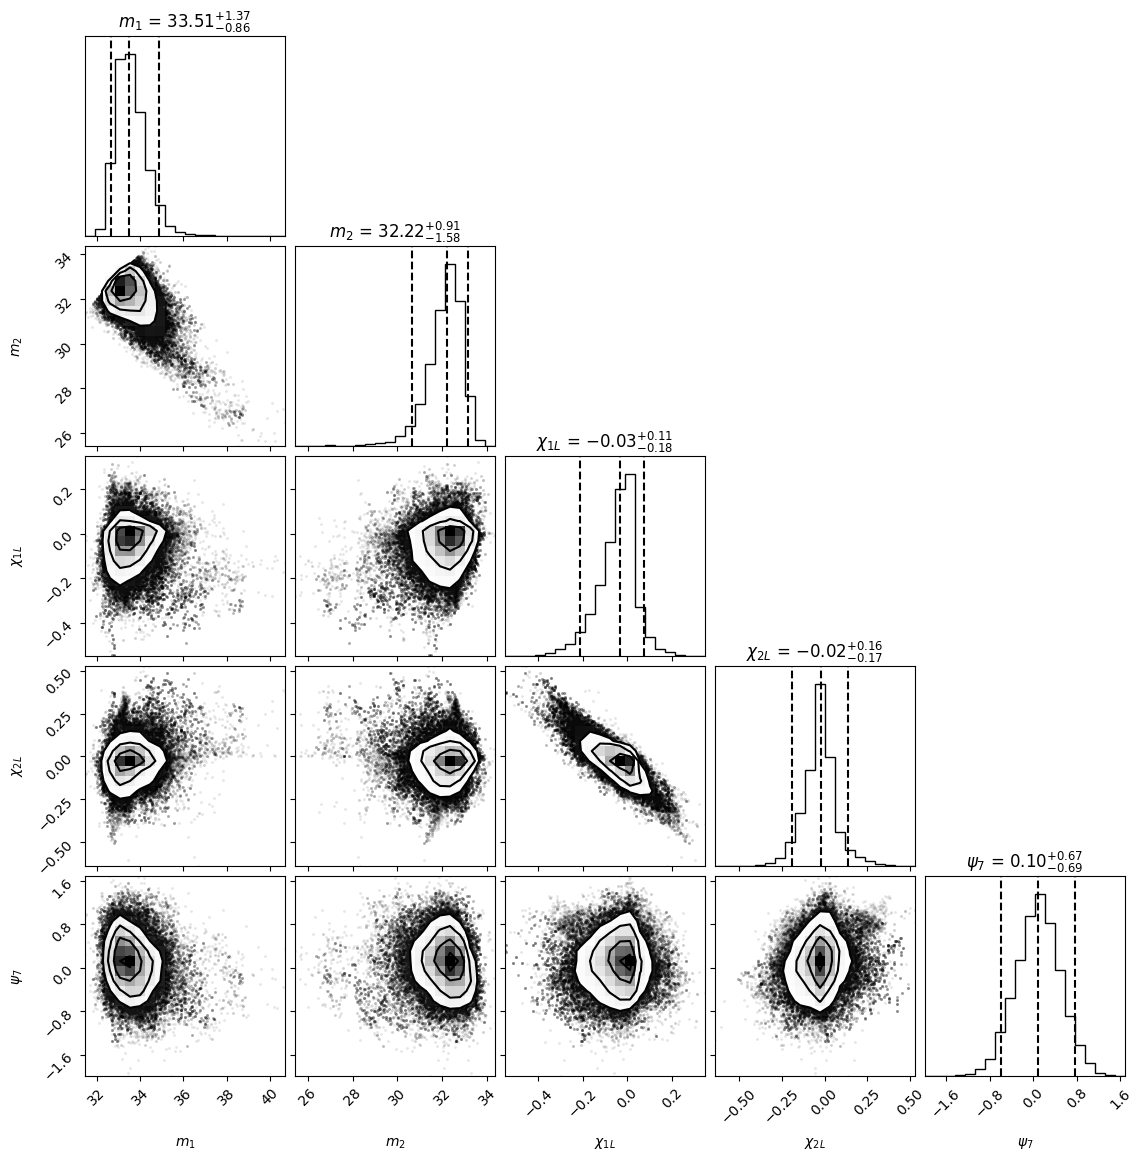

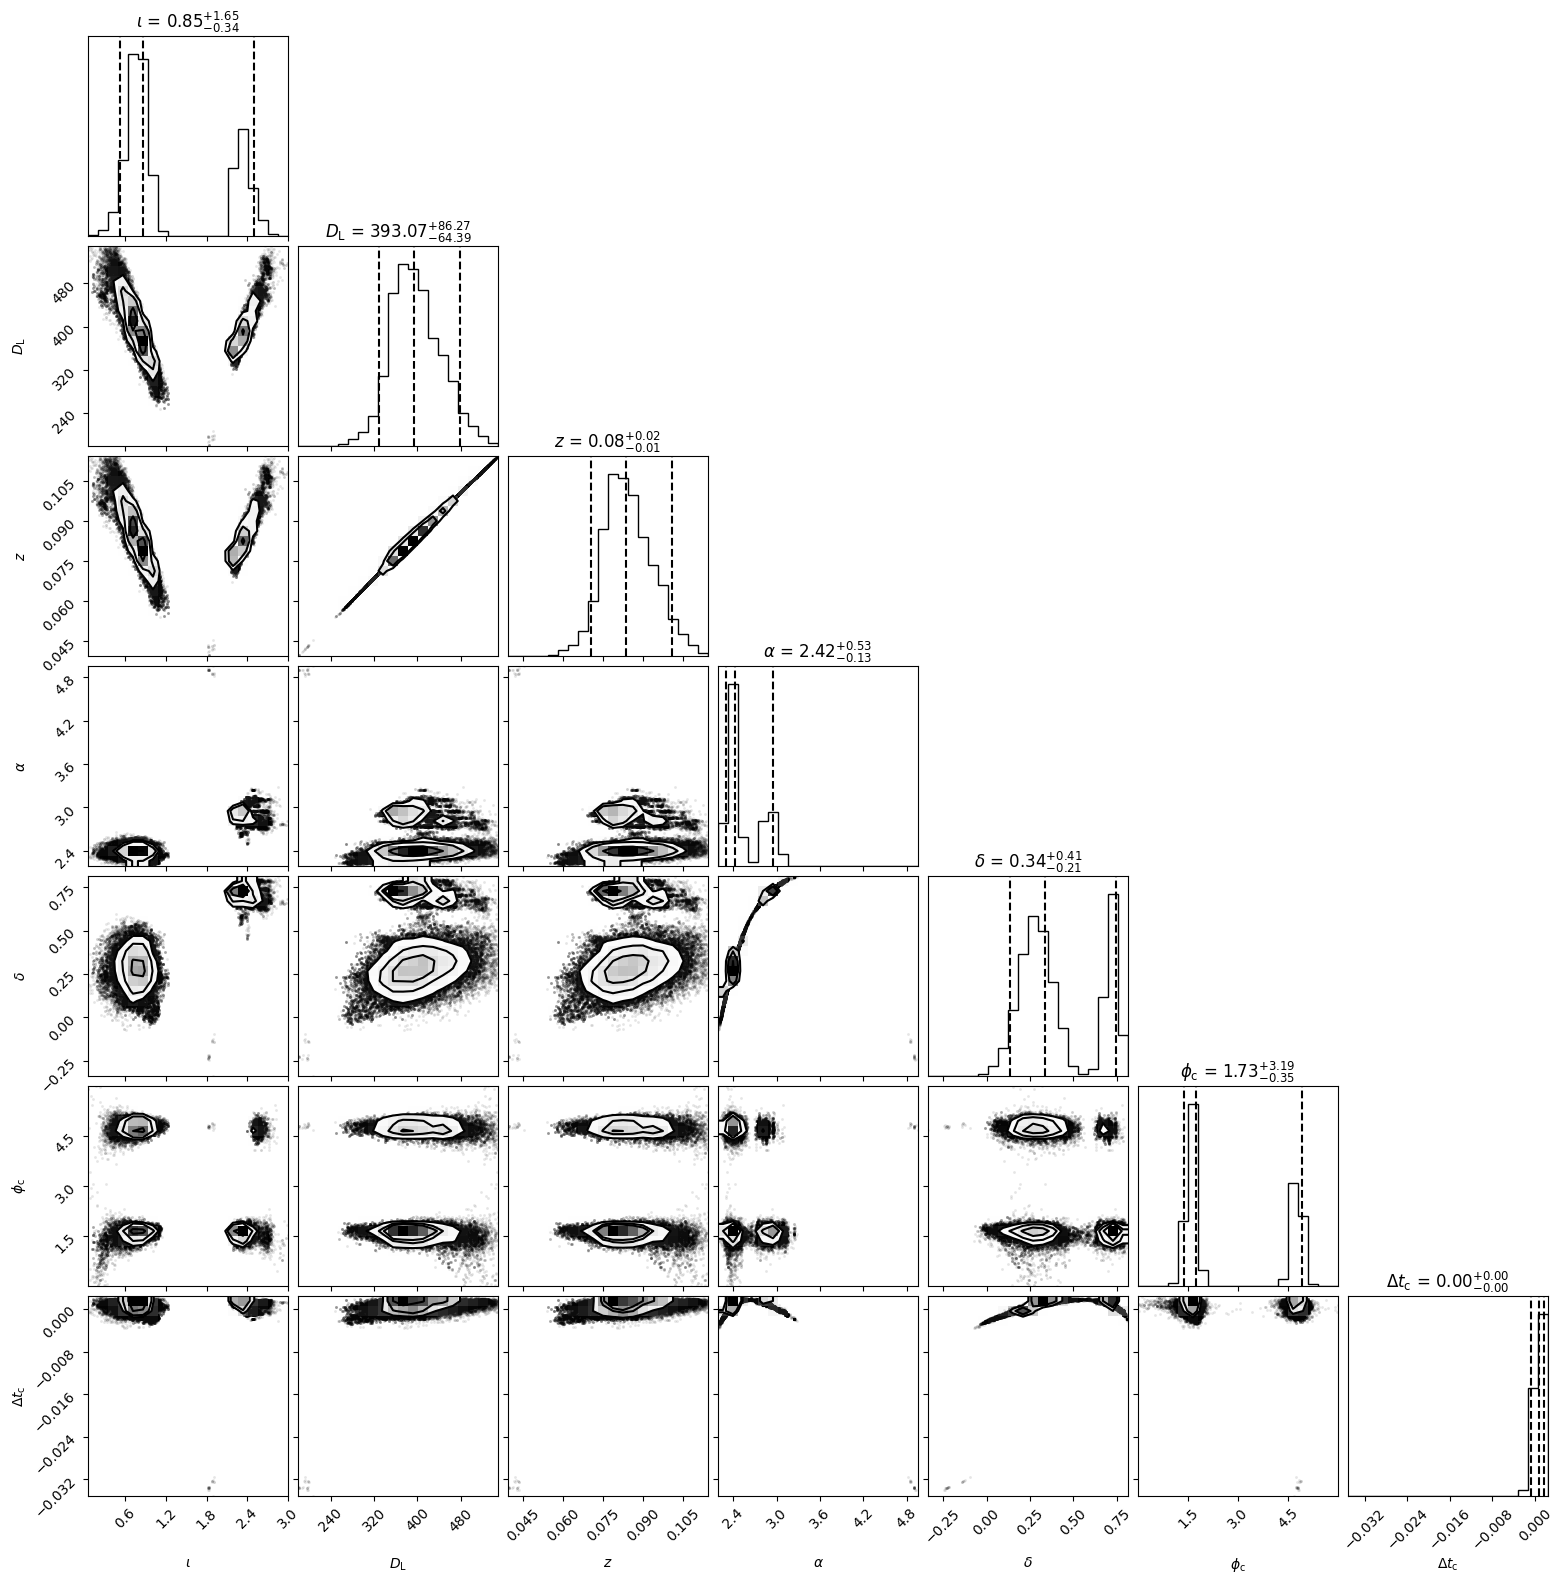

In [9]:
import os

fig_path = "/mnt/d/Documents/workspace/课题/论文/figs"
save_path = os.path.join(fig_path, event_id, "posteriors")

# 关键：不存在就创建，exist_ok=True 避免已存在时报错
os.makedirs(save_path, exist_ok=True)

print(f"文件夹已准备就绪：{save_path}")


quantiles = [0.05, 0.50, 0.95]
for j, cpsij in enumerate(dchijs) :
    if cpsij == "gr" :
        par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'inclination', 'distance', "redshift", "ra", "dec", 'coa_phase', "delta_tc"]
        corner.corner(samples[event_id][cpsij][par_list],
                      quantiles=quantiles,
                      show_titles=True,
                      #   title_kwargs={"fontsize":
                      hist_kwargs={"density": True},
                      labels=[r"$m_1$",r"$m_2$",r"$\chi_{1L}$",r"$\chi_{2L}$", r"$\hat{\chi}_\text{PN}$", r"$\iota$", r"$D_\text{L}$", r"$z$", r"$\alpha$", r"$\delta$", r"$\phi_\text{c}$", r"$\Delta t_\text{c}$"])
        pp.savefig(fig_path + "/" + event_id + "" + "/posteriors" + f"/" + event_id + "_posterior_gr.pdf")
        continue
    par_list = ['mass1', 'mass2','spin1z', 'spin2z', dchijs[j]]
    corner.corner(samples[event_id][cpsij][par_list],
                  quantiles=quantiles,
                  show_titles=True,
                  #   title_kwargs={"fontsize": 12},
                  hist_kwargs={"density": True},
                  labels=[r"$m_1$",r"$m_2$","$\chi_{{1L}}$","$\chi_{{2L}}$",f"$\\psi_{{{orders[j]}}}$"])
    pp.savefig(fig_path + "/" + event_id + "" + "/posteriors" + f"/" + event_id + f"_posterior_{cpsij}_0.pdf")
    
    par_list = ['inclination', 'distance', "redshift", "ra", "dec", 'coa_phase', "delta_tc"]
    corner.corner(samples[event_id][cpsij][par_list],
                  quantiles=quantiles,
                  show_titles=True,
                  #   title_kwargs={"fontsize": 12},
                  hist_kwargs={"density": True},
                  labels=[r"$\iota$", r"$D_\text{L}$", r"$z$", r"$\alpha$", r"$\delta$", r"$\phi_\text{c}$", r"$\Delta t_\text{c}$"])
    pp.savefig(fig_path + "/" + event_id + "" + "/posteriors" + f"/" + event_id + f"_posterior_{cpsij}_1.pdf")
    
pp.show()

In [10]:
# par_list = ['mass1', 'mass2', 'chi_hat_PN']
# corner.corner(samples[event_id]['gr'][par_list], labels=[r"$m_1$",r"$m_2$",r"$\hat{\chi}_\text{PN}$"])
# pp.savefig(fig_path + "/GW150914" + "/posteriors" + "/GW150914_posterior_gr.pdf")
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi0']
# corner.corner(samples[event_id]['cpsi0'][par_list], labels=par_list)
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi1']
# corner.corner(samples[event_id]['cpsi1'][par_list], labels=par_list)
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi2']
# corner.corner(samples[event_id]['cpsi2'][par_list], labels=par_list)
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi3']
# corner.corner(samples[event_id]['cpsi3'][par_list], labels=par_list)
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi4']
# corner.corner(samples[event_id]['cpsi4'][par_list], labels=par_list)
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi5l']
# corner.corner(samples[event_id]['cpsi5l'][par_list], labels=par_list)
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi6']
# corner.corner(samples[event_id]['cpsi6'][par_list], labels=par_list)
# par_list = ['mass1', 'mass2', 'chi_hat_PN', 'dchi6l']
# corner.corner(samples[event_id]['cpsi6l'][par_list], labels=par_list)